  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=66c4f909ba18ac95d28666b58c1dba8855bb88a828a6a71fe79610398b61b4f3
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom
Dataset shape: (150, 4)

SOM training completed.


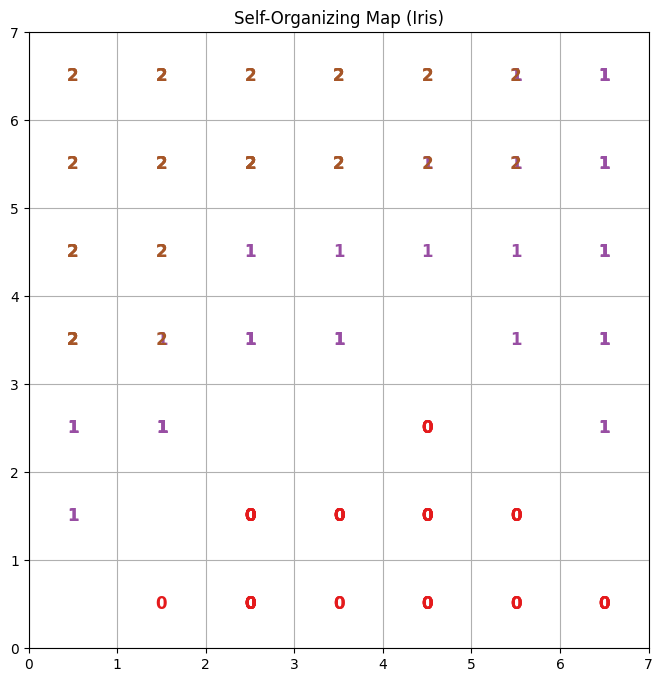

In [1]:
!pip install minisom pandas scikit-learn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom


iris = load_iris(as_frame=True)
X = iris.data.values # features
y = iris.target.values # labels (not used for training, but for visualization)

print("Dataset shape:", X.shape)


scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)


som_size = 7 # grid size (7x7 map)
som = MiniSom(x=som_size, y=som_size, input_len=X_scaled.shape[1],
              sigma=1.0, learning_rate=0.5, random_seed=42)

som.random_weights_init(X_scaled)
som.train_random(X_scaled, num_iteration=1000)

print("\nSOM training completed.")

plt.figure(figsize=(8, 8))
for i, x in enumerate(X_scaled):
    w = som.winner(x) # winning neuron for this sample
    plt.text(w[0]+0.5, w[1]+0.5, str(y[i]),
             color=plt.cm.Set1(y[i] / 3.),
             fontdict={'weight': 'bold', 'size': 12},
             horizontalalignment='center',
             verticalalignment='center')

plt.title("Self-Organizing Map (Iris)")
plt.xlim([0, som_size])
plt.ylim([0, som_size])
plt.grid(True)
plt.show()